# 06 — Hyperparameter-Analyse (HPA)

**Ziel**: Systematische Bayesianische Hyperparameter-Optimierung aller Modelle via **Optuna**  
**Metrik**: MAE (robust gegenüber Immobilien-Preisausreißern)  
**Datenbasis**: 1% stratifiziertes Sample (~117k Zeilen) aus `AUTO_final_enriched.parquet`  
**CV**: 3-Fold (Kompromiss Zeit / Stabilität)  
**Zeit-Budget**: max. 12h gesamt, per Modell via Optuna `timeout` kontrolliert  



> **Hinweis**: Tree-Modelle (LGBM, XGB) verarbeiten NaN nativ.  
> EBM / IGANN / LR / TabICL verwenden eine sklearn-Pipeline mit Imputation, um Data Leakage zu vermeiden.

In [17]:
# ==============================================================
# KONFIGURATION — Zentrale Einstellstelle für die gesamte HPA
# ==============================================================
CONFIG = {
    # --- Datenpfade (relativ zu ROOT = Workspace-Root) ---
    # ROOT wird in der Imports-Zelle via Path("..").resolve() gesetzt
    "data_path":    "data/processed/AUTO_final_enriched.parquet",
    "models_dir":   "models",

    # --- Sampling ---
    "sample_frac":  0.01,          # 1 % ≈ 117 k Zeilen
    "random_state": 42,

    # --- Cross-Validation ---
    "cv_folds":     3,             # 3-Fold spart ~40 % Zeit vs. 5-Fold
    "metric":       "mae",

    # --- Optuna Timeouts pro Studie (Sekunden) ---
    # Jede Studie läuft unabhängig für Price UND Duration
    "timeouts": {
        "lgbm":   30 * 60,        #  30 min / Target
        "xgb":    20 * 60,        #  20 min / Target
        "ebm":   200 * 60,        # 180 min / Target (jeder Trial ~30 min)
        "igann": 200 * 60,        # 200 min / Target
        "lr":      2 * 60,        #   2 min / Target
        "tabicl": 60 * 60,        #  60 min / Target (subsample!)
    },

    # --- TabICL spezifisch ---
    # In-Context-Learner: max. Datensatzgröße begrenzt, kein CUDA nötig
    "tabicl_max_rows": 5_000,

    # --- Targets ---
    "target_price":    "mietepro_m2",
    "target_duration": "log_laufzeittage",
}

print("CONFIG geladen ✓")
print(f"  Sample: {CONFIG['sample_frac']*100:.0f}% | CV: {CONFIG['cv_folds']}-Fold | Metric: {CONFIG['metric'].upper()}")
print(f"  Gesamt-Budget (geschätzt): ~{sum(CONFIG['timeouts'].values()) * 2 / 3600:.1f} h")


CONFIG geladen ✓
  Sample: 1% | CV: 3-Fold | Metric: MAE
  Gesamt-Budget (geschätzt): ~17.1 h


In [18]:
import sys
import os
import json
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import ks_2samp

from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import Ridge

import optuna
from optuna.samplers import TPESampler
from optuna.pruners import HyperbandPruner

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from interpret.glassbox import ExplainableBoostingRegressor
from igann import IGANN

# TabICL — wird gesondert behandelt, da möglicherweise nicht installiert
try:
    from tabicl import TabICLRegressor
    TABICL_AVAILABLE = True
    print("TabICL importiert ✓")
except ImportError:
    TABICL_AVAILABLE = False
    print("⚠️  TabICL nicht gefunden. Installiere mit: pip install tabicl")
    print("   → TabICL-Sektion wird übersprungen wenn nicht installiert.")

# Projekt-src in den Path aufnehmen
ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.preprocessing import (
    FEATURE_COLS,
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
    BINARY_FEATURES,
    OHE_FEATURES,
    LR_DROP_FEATURES,
    TARGET_PRICE,
    TARGET_DURATION,
    prepare_features,
    stratified_sample,
)

# Globale Einstellungen
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="muted")

print("Alle Imports erfolgreich ✓")
print(f"  Features: {len(FEATURE_COLS)} | Numerisch: {len(NUMERICAL_FEATURES)} | "
      f"Kategorisch: {len(CATEGORICAL_FEATURES)} | Binär: {len(BINARY_FEATURES)}")

TabICL importiert ✓
Alle Imports erfolgreich ✓
  Features: 32 | Numerisch: 16 | Kategorisch: 5 | Binär: 11


## 1 · Datenladen & Stratifiziertes Sampling

1% Sample, stratifiziert nach `ajahr` (Angebotsjahr) via `stratified_sample()` aus `src.data.preprocessing`.  
Anschließend KS-Test zur Validierung der Repräsentativität beider Zielvariablen.

In [19]:
# --- Volldatensatz laden (nur nötige Spalten für Effizienz) ---
needed_cols = FEATURE_COLS + [TARGET_PRICE, TARGET_DURATION, "ajahr"]
needed_cols = list(dict.fromkeys(needed_cols))  # Duplikate entfernen, Reihenfolge bewahren

print("Lade Parquet …")
t0 = time.time()
df_full = pd.read_parquet(
    ROOT / CONFIG["data_path"],
    columns=needed_cols,
)
print(f"  Geladen in {time.time()-t0:.1f}s | Shape: {df_full.shape}")

# --- Stratifiziertes 1%-Sample ---
print(f"\nErstelle {CONFIG['sample_frac']*100:.0f}%-Sample (stratifiziert nach ajahr) …")
df = stratified_sample(df_full, frac=CONFIG["sample_frac"], seed=CONFIG["random_state"])
print(f"  Sample-Shape (vor Filter): {df.shape}")

# --- Temporaler Filter: HPO nur auf Trainings-Jahren (kein Leakage durch Testdaten) ---
TEMPORAL_CUTOFF_HPO = 2021
df = df[df["ajahr"] <= TEMPORAL_CUTOFF_HPO].reset_index(drop=True)
print(f"  Temporaler Filter (ajahr ≤ {TEMPORAL_CUTOFF_HPO}): {df.shape}")

# --- Speicher freigeben ---
del df_full
print("\nVoll-DataFrame aus RAM entfernt ✓")

# --- Übersicht ---
print(f"\nZielvariablen im HPO-Sample (ajahr ≤ {TEMPORAL_CUTOFF_HPO}):")
print(df[[TARGET_PRICE, TARGET_DURATION]].describe().round(3))


Lade Parquet …
  Geladen in 0.8s | Shape: (11505472, 34)

Erstelle 1%-Sample (stratifiziert nach ajahr) …
  Sample-Shape (vor Filter): (115055, 34)
  Temporaler Filter (ajahr ≤ 2021): (92078, 34)

Voll-DataFrame aus RAM entfernt ✓

Zielvariablen im HPO-Sample (ajahr ≤ 2021):
       mietepro_m2  log_laufzeittage
count    92078.000         92078.000
mean         7.954             2.799
std          3.511             1.151
min          3.722             0.693
25%          5.504             2.079
50%          7.000             2.773
75%          9.389             3.555
max         26.500             7.883


KS-Test: Sample vs. Vollpopulation
  mietepro_m2                KS=0.0781  p=0.0000  ✗ FAIL — Sample nicht repräsentativ!
  log_laufzeittage           KS=0.0254  p=0.0000  ✗ FAIL — Sample nicht repräsentativ!


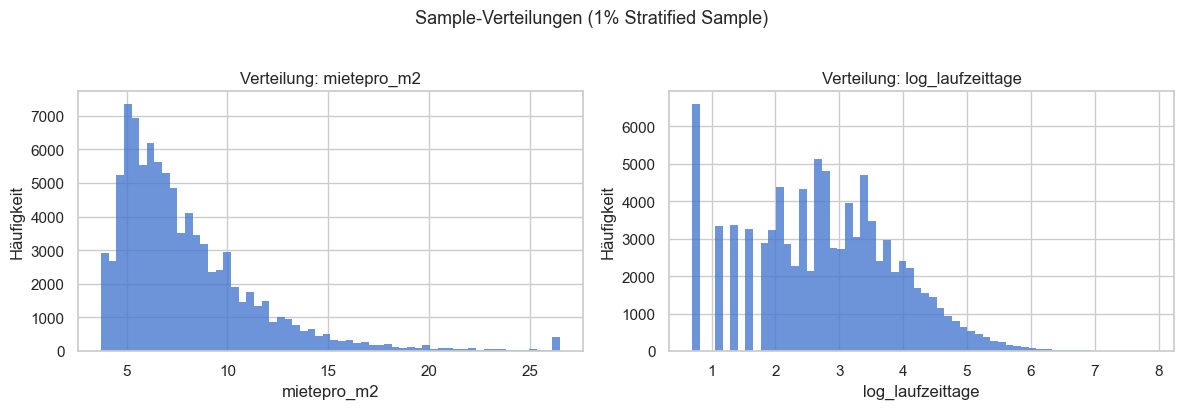

In [ ]:
# --- Sample-Validierung via KS-Test ---
df_targets_full = pd.read_parquet(
    ROOT / CONFIG["data_path"],
    columns=[TARGET_PRICE, TARGET_DURATION],
)

ALPHA = 0.05
print("KS-Test: Sample vs. Vollpopulation\n" + "="*45)
results_ks = {}
for target in [TARGET_PRICE, TARGET_DURATION]:
    full_clean = df_targets_full[target].dropna()
    sample_clean = df[target].dropna()
    stat, pval = ks_2samp(
        full_clean.sample(n=min(50_000, len(full_clean)), random_state=42),
        sample_clean,
    )
    status = "✓ PASS" if pval > ALPHA else "✗ FAIL — Sample nicht repräsentativ!"
    results_ks[target] = {"stat": stat, "p-value": pval, "status": status}
    print(f"  {target:25s}  KS={stat:.4f}  p={pval:.4f}  {status}")

del df_targets_full

# --- Verteilungsplot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, [TARGET_PRICE, TARGET_DURATION]):
    ax.hist(df[target].dropna(), bins=60, edgecolor="none", alpha=0.8)
    ax.set_title(f"Verteilung: {target}")
    ax.set_xlabel(target)
    ax.set_ylabel("Häufigkeit")
plt.suptitle("Sample-Verteilungen (1% Stratified Sample)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 2 · Preprocessing & Daten-Vorbereitung

**Zwei Feature-Matrizen** werden erzeugt:
- `X_tree`: Rohe Features mit NaN (für LGBM/XGB, die NaN nativ verarbeiten)
- Für EBM / IGANN / LR / TabICL: sklearn-`Pipeline` mit Imputation **innerhalb** der CV-Folds → kein Data Leakage

Ein gemeinsamer `make_pipeline()` Helper baut die korrekte Preprocessing-Pipeline für Nicht-Baum-Modelle.

In [ ]:
# --- Feature-Matrix (roh, für Baum-Modelle mit NaN-Handling) ---
X_tree = prepare_features(df)

# --- Zielvariablen ---
y_price    = df[TARGET_PRICE].values
y_duration = df[TARGET_DURATION].values

print(f"X_tree shape:   {X_tree.shape}")
print(f"y_price shape:  {y_price.shape}  | Median: {np.median(y_price):.2f} €/m²")
print(f"y_duration shape: {y_duration.shape} | Median: {np.median(y_duration):.3f} (log Tage)")

# --- Preprocessing-Pipeline für Nicht-Baum-Modelle ---

def make_preprocessor() -> ColumnTransformer:
    """
    Sklearn ColumnTransformer:
    - Numerisch:    Median-Imputation
    - Kategorisch:  Most-Frequent-Imputation + Ordinal-Encoding
    - Binär:        Most-Frequent-Imputation (bereits 0/1, nur NaN-Handling)
    """
    num_pipe = SimpleImputer(strategy="median")

    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        )),
    ])

    bin_pipe = SimpleImputer(strategy="most_frequent")

    return ColumnTransformer(
        transformers=[
            ("num", num_pipe, NUMERICAL_FEATURES),
            ("cat", cat_pipe, CATEGORICAL_FEATURES),
            ("bin", bin_pipe, BINARY_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def make_lr_preprocessor() -> ColumnTransformer:
    """Sklearn ColumnTransformer fuer Ridge (identisch zu prepare_features_for_linear in NB03/04).

    - Numerisch:    Median-Imputation
    - OHE_FEATURES: Most-Frequent-Imputation + OneHotEncoder(drop=first)  [ohne erg_amd]
    - Binaer:       Most-Frequent-Imputation
    - erg_amd:      DROPPED (141 Kategorien -> zu hohe Dimensionalitaet fuer Ridge)
    -> optimiertes alpha direkt auf NB03/04 X_train_lr uebertragbar (CRITICAL-2 geloest).
    """
    num_pipe = SimpleImputer(strategy="median")

    ohe_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False,
            dtype=float,
        )),
    ])

    bin_pipe = SimpleImputer(strategy="most_frequent")

    return ColumnTransformer(
        transformers=[
            ("num", num_pipe, NUMERICAL_FEATURES),
            ("ohe", ohe_pipe, OHE_FEATURES),    # objektzustand, heizungsart, kategorie_Wohnung, blid
            ("bin", bin_pipe, BINARY_FEATURES),
            # erg_amd fehlt bewusst -> remainder=drop entfernt es
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def make_ebm_preprocessor() -> ColumnTransformer:
    """EBM-Preprocessor: nur Imputation, kein Encoding (identisch zu X_train_imp in NB03/04).

    ExplainableBoostingRegressor verarbeitet str-Kategorien nativ.
    Kein OrdinalEncoder -> EBM sieht dieselben Daten wie beim finalen Training.
    erg_amd wird BEHALTEN (EBM ist Gruppe 2a, nicht 2b).
    """
    num_pipe = SimpleImputer(strategy="median")
    cat_pipe = SimpleImputer(strategy="most_frequent")   # str bleibt str
    bin_pipe = SimpleImputer(strategy="most_frequent")

    return ColumnTransformer(
        transformers=[
            ("num", num_pipe, NUMERICAL_FEATURES),
            ("cat", cat_pipe, CATEGORICAL_FEATURES),   # inkl. erg_amd
            ("bin", bin_pipe, BINARY_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

# --- MAE-Scorer (negativ für sklearn, minimieren für Optuna) ---
mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)

# --- 3-Fold CV-Splitter (shuffle=False: HPO-Daten nach ajahr geordnet → chronologische Folds) ---
kf = KFold(n_splits=CONFIG["cv_folds"], shuffle=False)

print("\nPreprocessing-Setup abgeschlossen ✓")


X_tree shape:   (92078, 32)
y_price shape:  (92078,)  | Median: 7.00 €/m²
y_duration shape: (92078,) | Median: 2.773 (log Tage)

Preprocessing-Setup abgeschlossen ✓


## 3 · Optuna-Framework & gemeinsame Hilfsfunktionen

Alle Modell-Sektionen nutzen dieselben Helper:
- `run_study()`: Erstellt und speichert eine Optuna-Studie mit TPE-Sampler + Timeout
- `save_best_params()`: Speichert beste Parameter als JSON in `models/`
- `save_trials_csv()`: Exportiert die vollständige Trial-Historie
- `print_study_summary()`: Ausgabe der besten Trial-Ergebnisse

In [22]:
MODELS_DIR = Path(ROOT / CONFIG["models_dir"])

# Globales Results-Dict: wird nach jeder Sektion befüllt
# Format: results[model_name][target] = {"mae": float, "best_params": dict, "n_trials": int}
hpa_results: dict = {}


def run_study(
    objective_fn,
    study_name: str,
    timeout_s: int,
    warm_start_params: dict | None = None,
) -> optuna.Study:
    """
    Erstellt eine Optuna-Studie mit TPE-Sampler und führt sie mit Timeout aus.

    Args:
        objective_fn:      Optuna-Objective-Funktion (trial → float)
        study_name:        Name der Studie (für Logging)
        timeout_s:         Maximale Laufzeit in Sekunden
        warm_start_params: Optionale Parameter für enqueue_trial() (Warm-Start)

    Returns:
        Abgeschlossene optuna.Study
    """
    study = optuna.create_study(
        direction="minimize",
        sampler=TPESampler(seed=CONFIG["random_state"]),
        study_name=study_name,
    )

    if warm_start_params:
        study.enqueue_trial(warm_start_params)
        print(f"  → Warm-Start-Trial eingereiht: {warm_start_params}")

    t_start = time.time()
    print(f"  Starte Optimierung [{study_name}] | Timeout: {timeout_s//60} min …")

    study.optimize(
        objective_fn,
        timeout=timeout_s,
        show_progress_bar=False,
        catch=(Exception,),  # fehlgeschlagene Trials nicht abbrechen
    )

    elapsed = time.time() - t_start
    n_complete = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
    if n_complete == 0:
        print(f"  ⚠️  Kein Trial erfolgreich abgeschlossen nach {elapsed/60:.1f} min!")
    else:
        print(f"  Abgeschlossen: {n_complete} Trials in {elapsed/60:.1f} min | "
              f"Bestes MAE: {study.best_value:.4f}")
    return study


def save_best_params(study: optuna.Study, filename: str) -> None:
    """Speichert beste Parameter als JSON."""
    path = MODELS_DIR / filename
    with open(path, "w", encoding="utf-8") as f:
        json.dump(study.best_params, f, indent=2)
    print(f"  Gespeichert: {path.name}")


def save_trials_csv(study: optuna.Study, filename: str) -> None:
    """Speichert alle Trials als CSV."""
    path = MODELS_DIR / filename
    study.trials_dataframe().to_csv(path, index=False)
    print(f"  Gespeichert: {path.name}")


def store_result(model_name: str, target: str, study: optuna.Study) -> None:
    """Trägt Ergebnis ins globale hpa_results-Dict ein."""
    if model_name not in hpa_results:
        hpa_results[model_name] = {}
    n_complete = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
    hpa_results[model_name][target] = {
        "mae":         study.best_value,
        "best_params": study.best_params,
        "n_trials":    n_complete,
    }


def cv_mae(model, X, y) -> float:
    """
    Führt 3-Fold-CV durch und gibt den mittleren MAE zurück.
    Nutzt den globalen `kf`-Splitter.
    """
    scores = cross_val_score(model, X, y, cv=kf, scoring=mae_scorer, n_jobs=1)
    return float(-scores.mean())

print("Optuna-Helpers definiert ✓")


Optuna-Helpers definiert ✓


## A · LightGBM HPA

**Search Space**: 8 Parameter | **n_jobs=-1** (nutzt alle 6 CPU-Kerne intern)  
**Warm-Start**: aus `best_params_lgbm_price.json` / `best_params_lgbm_duration.json`  
**Timeout**: 10 min pro Target

In [ ]:
# --- Warm-Start-Params laden ---
def load_warm_start(filename: str) -> dict | None:
    path = MODELS_DIR / filename
    if path.exists():
        with open(path) as f:
            return json.load(f)
    return None

lgbm_warm_price    = load_warm_start("best_params_lgbm_price.json")
lgbm_warm_duration = load_warm_start("best_params_lgbm_duration.json")
print(f"LGBM Warm-Start Price:    {lgbm_warm_price}")
print(f"LGBM Warm-Start Duration: {lgbm_warm_duration}")


def _lgbm_objective(trial, X, y) -> float:
    """Optuna-Objective fuer LightGBM (minimiert MAE via 3-Fold CV).
    
    X_tree enthaelt str-typisierte Kategorien (V1.5 defensives Encoding).
    make_preprocessor() uebernimmt Imputation + OrdinalEncoding fuer LGBM.
    """
    params = {
        "n_estimators":    trial.suggest_int("n_estimators", 100, 1500),
        "learning_rate":   trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "max_depth":       trial.suggest_int("max_depth", 3, 12),
        "num_leaves":      trial.suggest_int("num_leaves", 20, 300),
        "subsample":       trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha":       trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda":      trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "n_jobs":          -1,
        "random_state":    CONFIG["random_state"],
        "verbose":         -1,
    }
    # Pipeline: make_preprocessor() kodiert str-Spalten via OrdinalEncoder

    model = Pipeline([
        ("pre",  make_preprocessor()),
        ("lgbm", LGBMRegressor(**params)),
    ])
    return cv_mae(model, X, y)


print("\n--- LightGBM: Target = mietepro_m2 ---")
lgbm_study_price = run_study(
    objective_fn=lambda t: _lgbm_objective(t, X_tree, y_price),
    study_name="lgbm_price",
    timeout_s=CONFIG["timeouts"]["lgbm"],
    warm_start_params=lgbm_warm_price,
)
save_best_params(lgbm_study_price, "best_params_lgbm_price.json")
save_trials_csv(lgbm_study_price,  "hpa_trials_lgbm_price.csv")
store_result("LightGBM", TARGET_PRICE, lgbm_study_price)

print("\n--- LightGBM: Target = log_laufzeittage ---")
lgbm_study_dur = run_study(
    objective_fn=lambda t: _lgbm_objective(t, X_tree, y_duration),
    study_name="lgbm_duration",
    timeout_s=CONFIG["timeouts"]["lgbm"],
    warm_start_params=lgbm_warm_duration,
)
save_best_params(lgbm_study_dur, "best_params_lgbm_duration.json")
save_trials_csv(lgbm_study_dur,  "hpa_trials_lgbm_duration.csv")
store_result("LightGBM", TARGET_DURATION, lgbm_study_dur)

print("\nLightGBM HPA abgeschlossen")


LGBM Warm-Start Price:    {'n_estimators': 1279, 'learning_rate': 0.04398839992499262, 'max_depth': 12, 'num_leaves': 244, 'subsample': 0.7348897171928255, 'colsample_bytree': 0.8717999158860598, 'reg_alpha': 4.6487656611472643e-07, 'reg_lambda': 2.248438908448506e-08}
LGBM Warm-Start Duration: {'n_estimators': 1392, 'learning_rate': 0.027728084526200476, 'max_depth': 11, 'num_leaves': 20, 'subsample': 0.7446874341125324, 'colsample_bytree': 0.6002690991669386, 'reg_alpha': 8.920408547279305, 'reg_lambda': 7.380343021221993}

--- LightGBM: Target = mietepro_m2 ---
  → Warm-Start-Trial eingereiht: {'n_estimators': 1279, 'learning_rate': 0.04398839992499262, 'max_depth': 12, 'num_leaves': 244, 'subsample': 0.7348897171928255, 'colsample_bytree': 0.8717999158860598, 'reg_alpha': 4.6487656611472643e-07, 'reg_lambda': 2.248438908448506e-08}
  Starte Optimierung [lgbm_price] | Timeout: 30 min …
  Abgeschlossen: 151 Trials in 30.2 min | Bestes MAE: 1.3512
  Gespeichert: best_params_lgbm_price

## B · XGBoost HPA

**Search Space**: 8 Parameter | `tree_method='hist'` für CPU-optimierte Berechnung  
**Warm-Start**: aus `best_params_xgb_price.json` / `best_params_xgb_duration.json`  
**Timeout**: 20 min pro Target

In [8]:
xgb_warm_price    = load_warm_start("best_params_xgb_price.json")
xgb_warm_duration = load_warm_start("best_params_xgb_duration.json")
print(f"XGB Warm-Start Price:    {xgb_warm_price}")
print(f"XGB Warm-Start Duration: {xgb_warm_duration}")


def _xgb_objective(trial, X, y) -> float:
    """Optuna-Objective fuer XGBoost (minimiert MAE via 3-Fold CV).

    X_tree enthaelt str-typisierte Kategorien (V1.5 defensives Encoding).
    make_preprocessor() uebernimmt Imputation + OrdinalEncoding.
    Ohne Encoding crasht XGBRegressor mit str-Spalten (kein enable_categorical=True).
    """
    params = {
        "n_estimators":    trial.suggest_int("n_estimators", 100, 1500),
        "learning_rate":   trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "max_depth":       trial.suggest_int("max_depth", 3, 10),
        "subsample":       trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha":       trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda":      trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "min_child_weight":trial.suggest_int("min_child_weight", 1, 10),
        "tree_method":     "hist",
        "device":          "cpu",
        "nthread":         -1,
        "random_state":    CONFIG["random_state"],
        "verbosity":       0,
    }
    # Pipeline: make_preprocessor() kodiert str-Spalten via OrdinalEncoder
    # -> identische Preprocessing-Kette wie im finalen Training (NB03/04 X_train_tree)
    model = Pipeline([
        ("pre", make_preprocessor()),
        ("xgb", XGBRegressor(**params)),
    ])
    return cv_mae(model, X, y)


print("\n--- XGBoost: Target = mietepro_m2 ---")
xgb_study_price = run_study(
    objective_fn=lambda t: _xgb_objective(t, X_tree, y_price),
    study_name="xgb_price",
    timeout_s=CONFIG["timeouts"]["xgb"],
    warm_start_params=xgb_warm_price,
)
save_best_params(xgb_study_price, "best_params_xgb_price.json")
save_trials_csv(xgb_study_price,  "hpa_trials_xgb_price.csv")
store_result("XGBoost", TARGET_PRICE, xgb_study_price)

print("\n--- XGBoost: Target = log_laufzeittage ---")
xgb_study_dur = run_study(
    objective_fn=lambda t: _xgb_objective(t, X_tree, y_duration),
    study_name="xgb_duration",
    timeout_s=CONFIG["timeouts"]["xgb"],
    warm_start_params=xgb_warm_duration,
)
save_best_params(xgb_study_dur, "best_params_xgb_duration.json")
save_trials_csv(xgb_study_dur,  "hpa_trials_xgb_duration.csv")
store_result("XGBoost", TARGET_DURATION, xgb_study_dur)

print("\nXGBoost HPA abgeschlossen")


XGB Warm-Start Price:    {'n_estimators': 1353, 'learning_rate': 0.04356049723101923, 'max_depth': 10, 'subsample': 0.8761281991666833, 'colsample_bytree': 0.7421530825467714, 'reg_alpha': 8.305330643409634e-06, 'reg_lambda': 0.0004975695075461775, 'min_child_weight': 7}
XGB Warm-Start Duration: {'n_estimators': 1402, 'learning_rate': 0.014876083545051452, 'max_depth': 10, 'subsample': 0.9267188279766823, 'colsample_bytree': 0.7209350556845003, 'reg_alpha': 2.1169807896580207e-07, 'reg_lambda': 0.001831932375279009, 'min_child_weight': 7}

--- XGBoost: Target = mietepro_m2 ---
  → Warm-Start-Trial eingereiht: {'n_estimators': 1353, 'learning_rate': 0.04356049723101923, 'max_depth': 10, 'subsample': 0.8761281991666833, 'colsample_bytree': 0.7421530825467714, 'reg_alpha': 8.305330643409634e-06, 'reg_lambda': 0.0004975695075461775, 'min_child_weight': 7}
  Starte Optimierung [xgb_price] | Timeout: 20 min …
  Abgeschlossen: 110 Trials in 20.0 min | Bestes MAE: 1.3510
  Gespeichert: best_pa

## C · EBM (Explainable Boosting Machine) HPA

**Search Space**: 5 Parameter | Sklearn-Pipeline mit Imputation (kein NaN-Handling nativ)  
**Warm-Start**: aus `best_params_ebm_price.json` / `best_params_ebm_duration.json`  
**Timeout**: 60 min pro Target (EBM ist deutlich langsamer als LGBM/XGB)

In [9]:
ebm_warm_price    = load_warm_start("best_params_ebm_price.json")
ebm_warm_duration = load_warm_start("best_params_ebm_duration.json")
print(f"EBM Warm-Start Price:    {ebm_warm_price}")
print(f"EBM Warm-Start Duration: {ebm_warm_duration}")


def _ebm_objective(trial, X, y) -> float:
    """Optuna-Objective für EBM (minimiert MAE via 3-Fold CV mit Pipeline)."""
    params = {
        "max_bins":           trial.suggest_int("max_bins", 64, 512),
        "max_interaction_bins":trial.suggest_int("max_interaction_bins", 8, 64),
        "interactions":       trial.suggest_int("interactions", 0, 20),
        "learning_rate":      trial.suggest_float("learning_rate", 5e-3, 0.15, log=True),
        "min_samples_leaf":   trial.suggest_int("min_samples_leaf", 2, 20),
        "max_rounds":         trial.suggest_int("max_rounds", 1000, 5000),
        "random_state":       CONFIG["random_state"],
        "n_jobs":             1,        # EBM ist intern single-threaded
    }
    model = Pipeline([
        ("pre", make_ebm_preprocessor()),  # Gruppe 2a: nur Imputation, str-Cats bleiben str
        ("ebm", ExplainableBoostingRegressor(**params)),
    ])
    return cv_mae(model, X, y)


print("\n--- EBM: Target = mietepro_m2 ---")
ebm_study_price = run_study(
    objective_fn=lambda t: _ebm_objective(t, X_tree, y_price),
    study_name="ebm_price",
    timeout_s=CONFIG["timeouts"]["ebm"],
    warm_start_params=ebm_warm_price,
)
save_best_params(ebm_study_price, "best_params_ebm_price.json")
save_trials_csv(ebm_study_price,  "hpa_trials_ebm_price.csv")
store_result("EBM", TARGET_PRICE, ebm_study_price)

print("\n--- EBM: Target = log_laufzeittage ---")
ebm_study_dur = run_study(
    objective_fn=lambda t: _ebm_objective(t, X_tree, y_duration),
    study_name="ebm_duration",
    timeout_s=CONFIG["timeouts"]["ebm"],
    warm_start_params=ebm_warm_duration,
)
save_best_params(ebm_study_dur, "best_params_ebm_duration.json")
save_trials_csv(ebm_study_dur,  "hpa_trials_ebm_duration.csv")
store_result("EBM", TARGET_DURATION, ebm_study_dur)

print("\nEBM HPA abgeschlossen ✓")

EBM Warm-Start Price:    {'max_bins': 452, 'max_interaction_bins': 42, 'interactions': 14, 'learning_rate': 0.005362604871585998, 'min_samples_leaf': 20, 'max_rounds': 10492}
EBM Warm-Start Duration: {'max_bins': 452, 'max_interaction_bins': 42, 'interactions': 14, 'learning_rate': 0.005362604871585998, 'min_samples_leaf': 20, 'max_rounds': 10492}

--- EBM: Target = mietepro_m2 ---
  → Warm-Start-Trial eingereiht: {'max_bins': 452, 'max_interaction_bins': 42, 'interactions': 14, 'learning_rate': 0.005362604871585998, 'min_samples_leaf': 20, 'max_rounds': 10492}
  Starte Optimierung [ebm_price] | Timeout: 180 min …
  Abgeschlossen: 14 Trials in 194.7 min | Bestes MAE: 1.5099
  Gespeichert: best_params_ebm_price.json
  Gespeichert: hpa_trials_ebm_price.csv

--- EBM: Target = log_laufzeittage ---
  → Warm-Start-Trial eingereiht: {'max_bins': 452, 'max_interaction_bins': 42, 'interactions': 14, 'learning_rate': 0.005362604871585998, 'min_samples_leaf': 20, 'max_rounds': 10492}
  Starte Opt

## D · IGANN HPA

**Search Space**: 5 Parameter | PyTorch CPU-Training via sklearn-Pipeline  
**Warm-Start**: Manuelle Basisparameter aus bisheriger Nutzung (n_hid=256, n_estimators=3000, boost_rate=0.1, elm_scale=1.0)  
**Timeout**: 75 min pro Target

> IGANN ist der rechenintensivste Kandidat auf CPU. Die Warm-Start-Parameter kommen aus den bisherigen Notebooks (03/04) wo IGANN manuell konfiguriert wurde.

---
### Recovery-Setup (nach Kernel-Neustart)

Diese Zelle initialisiert alle Variablen neu, die IGANN und TabICL benötigen.  
**Ausführen wenn**: Kernel neugestartet und nur IGANN/TabICL nachgeholt werden sollen.

In [ ]:

# ================================================================
# RECOVERY-SETUP — initialisiert alle Abhängigkeiten neu
# Nur ausführen wenn Kernel neugestartet und IGANN/TabICL nachgeholt werden.
# ================================================================
import sys, json, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer, StandardScaler
from sklearn.linear_model import Ridge

import optuna
from optuna.samplers import TPESampler
from interpret.glassbox import ExplainableBoostingRegressor
from igann import IGANN

try:
    from tabicl import TabICLRegressor
    TABICL_AVAILABLE = True
except ImportError:
    TABICL_AVAILABLE = False

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.preprocessing import (
    FEATURE_COLS, NUMERICAL_FEATURES, CATEGORICAL_FEATURES,
    BINARY_FEATURES, TARGET_PRICE, TARGET_DURATION,
    prepare_features, stratified_sample,
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="muted")

# ---------------------------------------------------------------
# SKLEARN 1.6+ KOMPATIBILITÄTS-PATCHES für IGANN
# IGANN erbt nur von `object`, nicht von BaseEstimator.
# Pipeline.predict() in sklearn 1.6+ braucht __sklearn_tags__ und
# __sklearn_is_fitted__ → ohne diese Patches gibt jeder Trial 1e9 zurück.
# ---------------------------------------------------------------
from sklearn.utils._tags import Tags, TargetTags

if not hasattr(IGANN, "__sklearn_tags__"):
    def _igann_sklearn_tags(self):
        return Tags(estimator_type=None, target_tags=TargetTags(required=False))
    IGANN.__sklearn_tags__ = _igann_sklearn_tags
    print("  → IGANN.__sklearn_tags__ gepatcht")

if not hasattr(IGANN, "__sklearn_is_fitted__"):
    IGANN.__sklearn_is_fitted__ = lambda self: hasattr(self, "linear_model")
    print("  → IGANN.__sklearn_is_fitted__ gepatcht")

CONFIG = {
    "data_path":    "data/processed/AUTO_final_enriched.parquet",
    "models_dir":   "models",
    "sample_frac":  0.01,
    "random_state": 42,
    "cv_folds":     3,
    "metric":       "mae",
    "timeouts": {
        "igann":  200 * 60,
        "lr":      2 * 60,
        "tabicl": 60 * 60,
    },
    "tabicl_max_rows": 5_000,
    "target_price":    "mietepro_m2",
    "target_duration": "log_laufzeittage",
}

MODELS_DIR = ROOT / CONFIG["models_dir"]
hpa_results: dict = {}

# --- Daten laden & samplen ---
print("Lade Daten …")
needed_cols = list(dict.fromkeys(
    FEATURE_COLS + [TARGET_PRICE, TARGET_DURATION, "ajahr"]
))
df_full = pd.read_parquet(ROOT / CONFIG["data_path"], columns=needed_cols)
df = stratified_sample(df_full, frac=CONFIG["sample_frac"], seed=CONFIG["random_state"])
del df_full

# --- Temporaler Filter: HPO nur auf Trainings-Jahren (kein Leakage durch Testdaten) ---
TEMPORAL_CUTOFF_HPO = 2021
df = df[df["ajahr"] <= TEMPORAL_CUTOFF_HPO].reset_index(drop=True)
print(f"  Temporaler Filter (ajahr ≤ {TEMPORAL_CUTOFF_HPO}): {df.shape}")

X_tree    = prepare_features(df)
y_price   = df[TARGET_PRICE].values
y_duration= df[TARGET_DURATION].values
print(f"  Sample: {X_tree.shape} | y_price median={np.median(y_price):.2f}")

# --- Preprocessor & CV ---
def make_preprocessor() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERICAL_FEATURES),
            ("cat", Pipeline([
                ("imp", SimpleImputer(strategy="most_frequent")),
                ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
            ]), CATEGORICAL_FEATURES),
            ("bin", SimpleImputer(strategy="most_frequent"), BINARY_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def make_lr_preprocessor() -> ColumnTransformer:
    """Ridge-Preprocessor: OHE ohne erg_amd (identisch zu prepare_features_for_linear in NB03/04)."""
    from sklearn.preprocessing import OneHotEncoder
    from src.data.preprocessing import OHE_FEATURES
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERICAL_FEATURES),
            ("ohe", Pipeline([
                ("imp", SimpleImputer(strategy="most_frequent")),
                ("enc", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False, dtype=float)),
            ]), OHE_FEATURES),
            ("bin", SimpleImputer(strategy="most_frequent"), BINARY_FEATURES),
        ],
        remainder="drop", verbose_feature_names_out=False,
    )


def make_ebm_preprocessor() -> ColumnTransformer:
    """EBM: nur Imputation, str-Cats bleiben str (Gruppe 2a, identisch zu X_train_imp in NB03/04)."""
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERICAL_FEATURES),
            ("cat", SimpleImputer(strategy="most_frequent"), CATEGORICAL_FEATURES),
            ("bin", SimpleImputer(strategy="most_frequent"), BINARY_FEATURES),
        ],
        remainder="drop", verbose_feature_names_out=False,
    )

mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)
# shuffle=False: HPO-Daten nach ajahr geordnet → chronologische Folds, kein Look-ahead
kf = KFold(n_splits=CONFIG["cv_folds"], shuffle=False)

# --- Optuna-Helpers ---
def run_study(objective_fn, study_name, timeout_s, warm_start_params=None):
    study = optuna.create_study(
        direction="minimize",
        sampler=TPESampler(seed=CONFIG["random_state"]),
        study_name=study_name,
    )
    if warm_start_params:
        study.enqueue_trial(warm_start_params)
        print(f"  → Warm-Start eingereiht")
    t0 = time.time()
    print(f"  Starte [{study_name}] | Timeout: {timeout_s//60} min …")
    study.optimize(objective_fn, timeout=timeout_s,
                   show_progress_bar=False, catch=(Exception,))
    n = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
    elapsed = time.time() - t0
    if n == 0:
        print(f"   Kein Trial erfolgreich nach {elapsed/60:.1f} min!")
    else:
        print(f"  Abgeschlossen: {n} Trials in {elapsed/60:.1f} min | Bestes MAE: {study.best_value:.4f}")
    return study

def save_best_params(study, filename):
    n = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
    if n == 0:
        print(f"    Kein Trial — {filename} nicht überschrieben."); return
    p = MODELS_DIR / filename
    with open(p, "w") as f: json.dump(study.best_params, f, indent=2)
    print(f"  Gespeichert: {p.name}")

def save_trials_csv(study, filename):
    (MODELS_DIR / filename).parent.mkdir(parents=True, exist_ok=True)
    study.trials_dataframe().to_csv(MODELS_DIR / filename, index=False)
    print(f"  Gespeichert: {filename}")

def store_result(model_name, target, study):
    n = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
    if n == 0:
        print(f"    {model_name}/{target}: keine Ergebnisse."); return
    if model_name not in hpa_results: hpa_results[model_name] = {}
    hpa_results[model_name][target] = {
        "mae": study.best_value, "best_params": study.best_params, "n_trials": n,
    }

def cv_mae(model, X, y):
    scores = cross_val_score(model, X, y, cv=kf, scoring=mae_scorer, n_jobs=1)
    return float(-scores.mean())

def load_warm_start(filename):
    p = MODELS_DIR / filename
    if p.exists():
        with open(p) as f: return json.load(f)
    return None

print("\nRecovery-Setup abgeschlossen ✓")
print(f"  TabICL verfügbar: {TABICL_AVAILABLE}")


  → IGANN.__sklearn_tags__ gepatcht
  → IGANN.__sklearn_is_fitted__ gepatcht
Lade Daten …
  Temporaler Filter (ajahr ≤ 2021): (92078, 34)
  Sample: (92078, 32) | y_price median=7.00

Recovery-Setup abgeschlossen ✓
  TabICL verfügbar: True


In [2]:

# IGANN Warm-Start: bisherige manuelle Konfiguration aus Notebooks 03/04
# elm_alpha auf 1e-3 erhoeht (war 1e-4) -> verhindert singulaere ELM-Matrix
IGANN_WARM_START = {
    "n_hid":        64,
    "n_estimators": 500,
    "boost_rate":   0.1,
    "elm_scale":    1.0,
    "elm_alpha":    1e-3,
}
print(f"IGANN Warm-Start: {IGANN_WARM_START}")

# ---------------------------------------------------------------
# SKLEARN 1.6+ KOMPATIBILITÄTS-PATCHES für IGANN
# ---------------------------------------------------------------
# URSACHE DES HPA-VERSAGENS (diagnostiziert):
#   IGANN erbt nur von `object`, NICHT von sklearn.BaseEstimator.
#   sklearn 1.6+ ruft in Pipeline.predict() intern check_is_fitted() auf,
#   das wiederum get_tags(estimator) → estimator.__sklearn_tags__() braucht.
#   Da IGANN diese Methode nicht hat, wirft Pipeline.predict() AttributeError,
#   der von _igann_cv_mae lautlos per `except Exception` gefangen wird → 1e9.
#   IGANN.fit() läuft 3×16 min/Trial korrekt durch — nur die Prediction schlägt fehl.
#   In NB03/04 funktionierte es, weil IGANN dort DIREKT (ohne Pipeline) aufgerufen wurde.
# ---------------------------------------------------------------
from sklearn.utils._tags import Tags, TargetTags

if not hasattr(IGANN, "__sklearn_tags__"):
    def _igann_sklearn_tags(self):
        return Tags(estimator_type=None, target_tags=TargetTags(required=False))
    IGANN.__sklearn_tags__ = _igann_sklearn_tags
    print("  → IGANN.__sklearn_tags__ gepatcht (sklearn 1.6+ Kompatibilität)")

if not hasattr(IGANN, "__sklearn_is_fitted__"):
    # `linear_model` wird in IGANN.fit() gesetzt → zuverlässiger Fitted-Indikator
    IGANN.__sklearn_is_fitted__ = lambda self: hasattr(self, "linear_model")
    print("  → IGANN.__sklearn_is_fitted__ gepatcht")

# IGANN erwartet intern pandas DataFrame (X.iloc[...] in igann.py:395).
# Gruppe 2b (wie LR): OHE ohne erg_amd -> make_lr_preprocessor().
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def _to_igann_df(X_np):
    """numpy -> DataFrame mit NaN/Inf-Ersetzung fuer IGANN.

    - Dynamische Spaltennamen (integer-index): fuer HPA ausreichend.
    - Finale Shape-Function-Namen kommen aus NB03/04 (X_train_lr mit ohe.get_feature_names_out).
    """
    df = pd.DataFrame(X_np)   # integer-Spaltennamen
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.fillna(0.0)
    return df


# Grosser aber FINITER Fallback-Wert (float("inf") -> Optuna NaN-Error)
_IGANN_FALLBACK_MAE = 1e9


def _igann_cv_mae(pipeline, X, y):
    """Manueller CV-Loop fuer IGANN.

    IGANN ist inkompatibel mit sklearn 1.6+ (__sklearn_tags__ fehlt).
    cross_val_score -> Scorer -> check_is_fitted -> get_tags -> AttributeError
    -> alle CV-Scores NaN -> Optuna immer 1e9 -> sinnloser HPA.
    Dieser manuelle Loop umgeht das sklearn-Scorer-Framework vollstaendig.
    Die Sklearn-Patches oben beheben zusaetzlich Pipeline.predict().
    """
    maes = []
    for train_idx, val_idx in kf.split(X):
        X_tr = X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx]
        X_val = X.iloc[val_idx]  if hasattr(X, "iloc") else X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        try:
            pipeline.fit(X_tr, y_tr)
            y_pred = pipeline.predict(X_val)
            if not np.all(np.isfinite(y_pred)):
                return _IGANN_FALLBACK_MAE
            maes.append(mean_absolute_error(y_val, y_pred))
        except Exception as e:
            print(f"    [IGANN CV-Fold Fehler] {type(e).__name__}: {str(e)[:120]}")
            return _IGANN_FALLBACK_MAE
    if not maes:
        return _IGANN_FALLBACK_MAE
    result = float(np.mean(maes))
    return result if np.isfinite(result) else _IGANN_FALLBACK_MAE


def _igann_objective(trial, X, y):
    """IGANN HPO auf OHE-Features (Gruppe 2b: identisch zu X_train_lr in NB03/04).

    Pipeline: make_lr_preprocessor() -> StandardScaler -> DataFrame -> IGANN.
    Manueller CV-Loop (kein cross_val_score) wegen sklearn 1.6+ Inkompatibilitaet.
    """
    params = {
        "task":         "regression",
        "n_hid":        trial.suggest_int("n_hid", 64, 128, step=32),
        "n_estimators": trial.suggest_int("n_estimators", 500, 1000, step=250),
        "boost_rate":   trial.suggest_float("boost_rate", 0.01, 0.3, log=True),
        "elm_scale":    trial.suggest_float("elm_scale", 0.1, 3.0, log=True),
        "elm_alpha":    trial.suggest_float("elm_alpha", 1e-3, 1.0, log=True),
        "random_state": CONFIG["random_state"],
    }
    model = Pipeline([
        ("pre",    make_lr_preprocessor()),  # Gruppe 2b: OHE ohne erg_amd
        ("scaler", StandardScaler()),        # ELMs sind scale-sensitiv
        ("to_df",  FunctionTransformer(_to_igann_df)),
        ("igann",  IGANN(**params)),
    ])
    return _igann_cv_mae(model, X, y)


print("\n--- IGANN: Target = mietepro_m2 ---")
igann_study_price = run_study(
    objective_fn=lambda t: _igann_objective(t, X_tree, y_price),
    study_name="igann_price",
    timeout_s=CONFIG["timeouts"]["igann"],
    warm_start_params=IGANN_WARM_START,
)
save_best_params(igann_study_price, "best_params_igann_price.json")
save_trials_csv(igann_study_price,  "hpa_trials_igann_price.csv")
store_result("IGANN", TARGET_PRICE, igann_study_price)

print("\n--- IGANN: Target = log_laufzeittage ---")
igann_study_dur = run_study(
    objective_fn=lambda t: _igann_objective(t, X_tree, y_duration),
    study_name="igann_duration",
    timeout_s=CONFIG["timeouts"]["igann"],
    warm_start_params=IGANN_WARM_START,
)
save_best_params(igann_study_dur, "best_params_igann_duration.json")
save_trials_csv(igann_study_dur,  "hpa_trials_igann_duration.csv")
store_result("IGANN", TARGET_DURATION, igann_study_dur)

print("\nIGANN HPA abgeschlossen ✓")


IGANN Warm-Start: {'n_hid': 64, 'n_estimators': 500, 'boost_rate': 0.1, 'elm_scale': 1.0, 'elm_alpha': 0.001}

--- IGANN: Target = mietepro_m2 ---
  → Warm-Start eingereiht
  Starte [igann_price] | Timeout: 200 min …
  Abgeschlossen: 5 Trials in 274.5 min | Bestes MAE: 1.6788
  Gespeichert: best_params_igann_price.json
  Gespeichert: hpa_trials_igann_price.csv

--- IGANN: Target = log_laufzeittage ---
  → Warm-Start eingereiht
  Starte [igann_duration] | Timeout: 200 min …
  Abgeschlossen: 7 Trials in 231.2 min | Bestes MAE: 0.8914
  Gespeichert: best_params_igann_duration.json
  Gespeichert: hpa_trials_igann_duration.csv

IGANN HPA abgeschlossen ✓


## E · Linear Regression (Ridge) — Regularisierungs-Baseline

Sehr schnell. Dient als interpretierbare Baseline für den Ergebnisvergleich.  
**Search Space**: 1 Parameter (α) | **Timeout**: 2 min pro Target

In [12]:
def _lr_objective(trial, X, y) -> float:
    """Ridge auf OHE-Features (ohne erg_amd).

    Identische Preprocessing-Kette wie NB03/04 (prepare_features_for_linear):
    - 16 Numerisch (imputed, kein Encoding)
    - OHE auf objektzustand, heizungsart, kategorie_Wohnung, blid (drop=first)
    - 11 Binaer (imputed)
    - erg_amd DROPPED
    -> optimiertes alpha direkt auf NB03/04 X_train_lr uebertragbar.
    """
    alpha = trial.suggest_float("alpha", 1e-4, 1e4, log=True)
    model = Pipeline([
        ("pre",   make_lr_preprocessor()),   # OHE ohne erg_amd (identisch zu NB03/04)
        ("ridge", Ridge(alpha=alpha, random_state=CONFIG["random_state"])),
    ])
    return cv_mae(model, X, y)


print("--- Linear Regression (Ridge): Target = mietepro_m2 ---")
lr_study_price = run_study(
    objective_fn=lambda t: _lr_objective(t, X_tree, y_price),
    study_name="lr_price",
    timeout_s=CONFIG["timeouts"]["lr"],
)
save_best_params(lr_study_price, "best_params_lr_price.json")
store_result("Ridge", TARGET_PRICE, lr_study_price)

print("\n--- Linear Regression (Ridge): Target = log_laufzeittage ---")
lr_study_dur = run_study(
    objective_fn=lambda t: _lr_objective(t, X_tree, y_duration),
    study_name="lr_duration",
    timeout_s=CONFIG["timeouts"]["lr"],
)
save_best_params(lr_study_dur, "best_params_lr_duration.json")
store_result("Ridge", TARGET_DURATION, lr_study_dur)

print("\nRidge HPA abgeschlossen ✓")


--- Linear Regression (Ridge): Target = mietepro_m2 ---
  Starte [lr_price] | Timeout: 2 min …
  Abgeschlossen: 188 Trials in 2.0 min | Bestes MAE: 1.7536
  Gespeichert: best_params_lr_price.json

--- Linear Regression (Ridge): Target = log_laufzeittage ---
  Starte [lr_duration] | Timeout: 2 min …
  Abgeschlossen: 196 Trials in 2.0 min | Bestes MAE: 0.9223
  Gespeichert: best_params_lr_duration.json

Ridge HPA abgeschlossen ✓


## 4 · Ergebnisvergleich & Visualisierung

Zusammenfassung aller HPA-Ergebnisse:
- **MAE-Vergleichstabelle**: alle Modelle × beide Targets
- **Trial-Konvergenz-Plot**: Optuna optimization history (bestes MAE über Trials)
- **Parameter-Importance-Plot**: Optuna's FAnova-Analyse — welche Hyperparameter zählen wirklich?

HPA-ERGEBNISSE — 3-Fold CV MAE (Optimum je Modell/Target)
Modell           Target     MAE (CV)  Trials
 Ridge log_laufzeittage 9.223000e-01     196
 IGANN log_laufzeittage 1.000000e+09       2
 Ridge      mietepro_m2 1.753600e+00     188
 IGANN      mietepro_m2 1.000000e+09       2


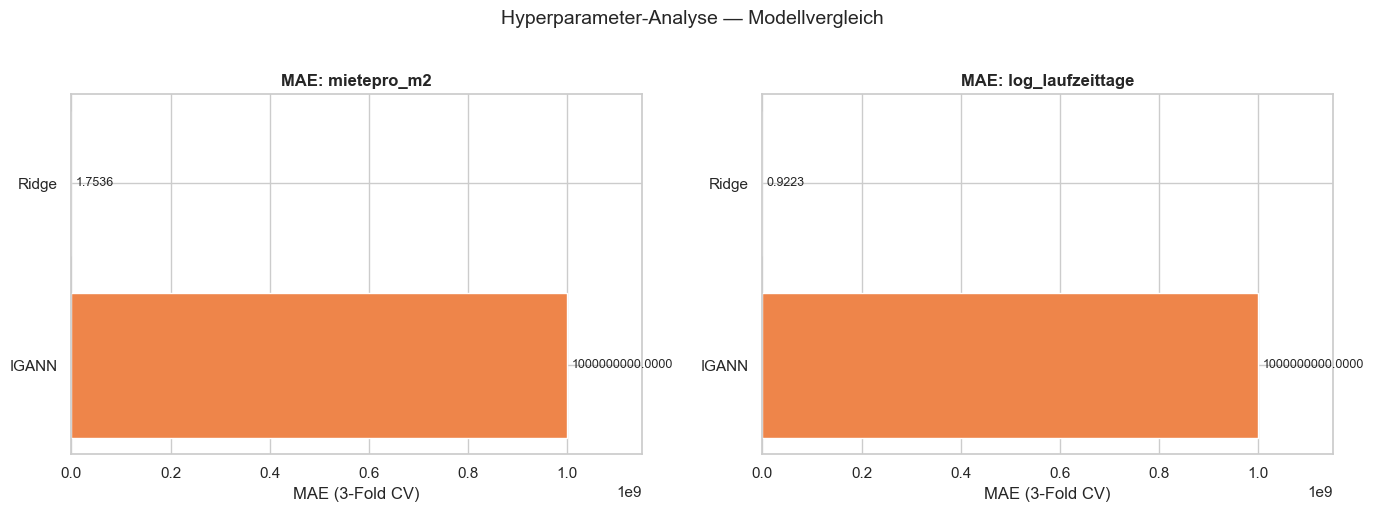

In [30]:

# --- MAE-Vergleichstabelle aus gespeicherter CSV (kernel-restart-sicher) ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

MODELS_DIR = Path("../models")
TARGET_PRICE    = "mietepro_m2"
TARGET_DURATION = "log_laufzeittage"

df_results = pd.read_csv(MODELS_DIR / "hpa_summary.csv")
df_results = df_results.sort_values(["Target", "MAE (CV)"]).reset_index(drop=True)

print("=" * 55)
print("HPA-ERGEBNISSE — 3-Fold CV MAE (Optimum je Modell/Target)")
print("=" * 55)
print(df_results.to_string(index=False))

# --- Übersichtsplot: MAE Barplot pro Target ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, target in zip(axes, [TARGET_PRICE, TARGET_DURATION]):
    sub = df_results[df_results["Target"] == target].sort_values("MAE (CV)")
    bars = ax.barh(sub["Modell"], sub["MAE (CV)"], color=sns.color_palette("muted", len(sub)))
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
    ax.set_title(f"MAE: {target}", fontsize=12, fontweight="bold")
    ax.set_xlabel("MAE (3-Fold CV)")
    ax.invert_yaxis()
    ax.set_xlim(0, sub["MAE (CV)"].max() * 1.15)
plt.suptitle("Hyperparameter-Analyse — Modellvergleich", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


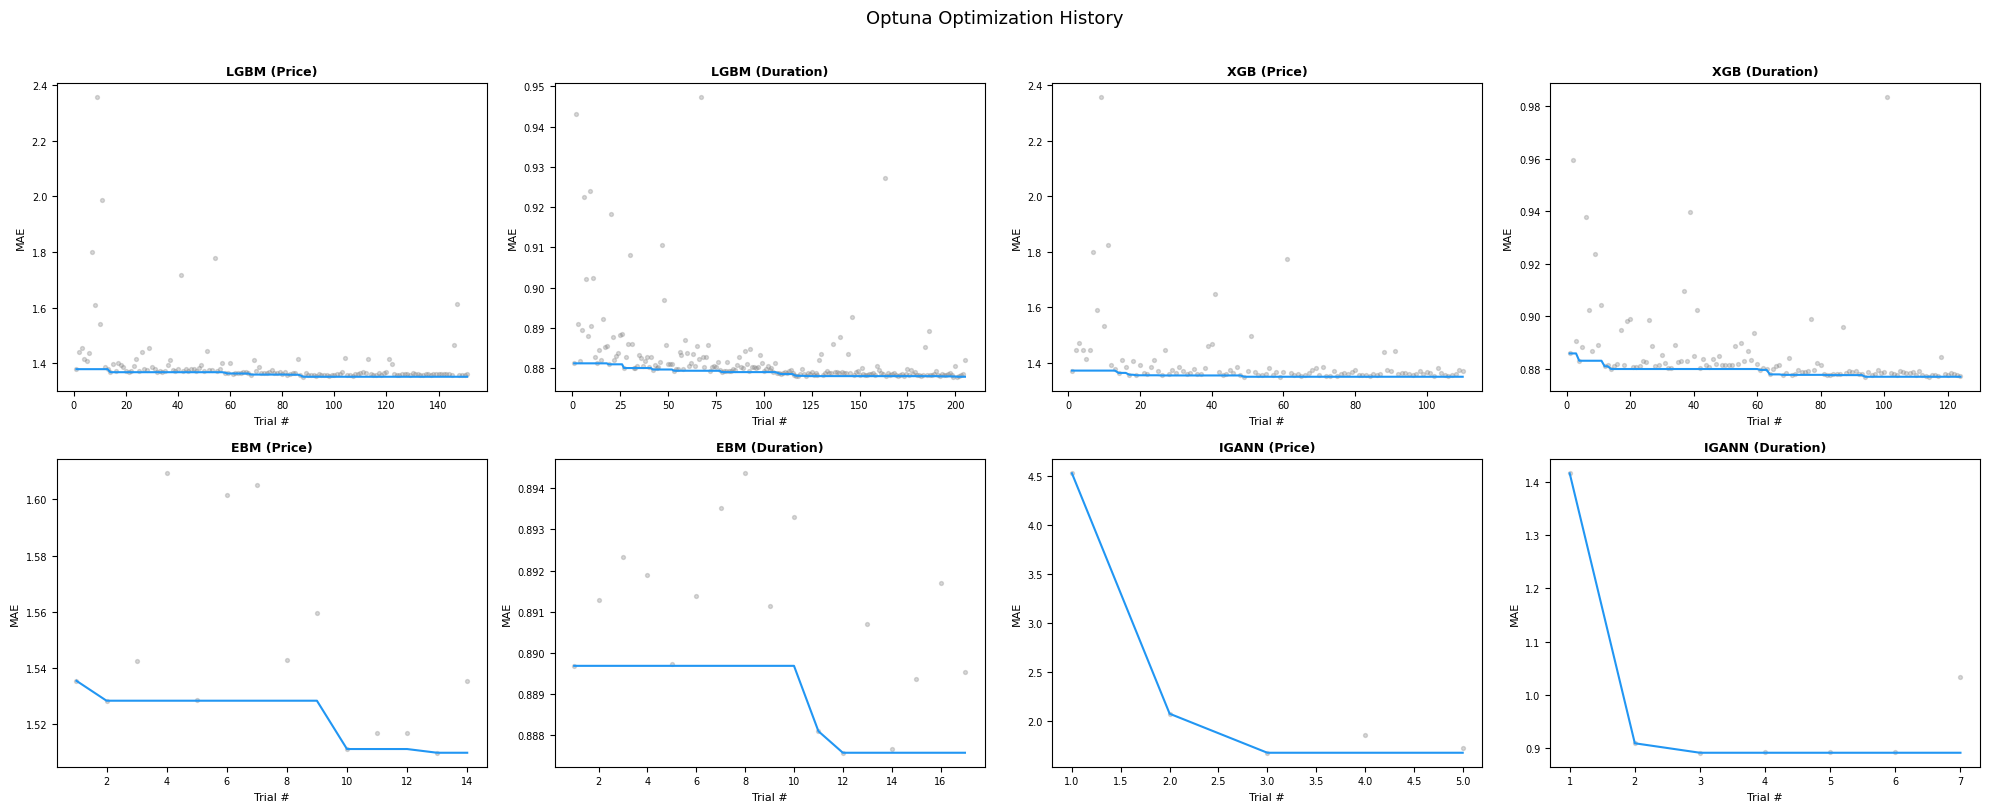

In [ ]:

# --- Optuna Optimization History aus gespeicherten Trial-CSVs  ---
# Ridge hat keine Trial-CSV (nur best_params gespeichert) → wird hier ausgelassen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("../models")

trial_files = {
    "LGBM (Price)":     "hpa_trials_lgbm_price.csv",
    "LGBM (Duration)":  "hpa_trials_lgbm_duration.csv",
    "XGB (Price)":      "hpa_trials_xgb_price.csv",
    "XGB (Duration)":   "hpa_trials_xgb_duration.csv",
    "EBM (Price)":      "hpa_trials_ebm_price.csv",
    "EBM (Duration)":   "hpa_trials_ebm_duration.csv",
    "IGANN (Price)":    "hpa_trials_igann_price.csv",
    "IGANN (Duration)": "hpa_trials_igann_duration.csv",
}

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes_flat = axes.flatten()

for ax, (name, fname) in zip(axes_flat, trial_files.items()):
    fpath = MODELS_DIR / fname
    if not fpath.exists():
        ax.text(0.5, 0.5, f"Keine Daten\n({fname})", ha="center", va="center",
                transform=ax.transAxes, fontsize=8)
        continue
    df_t = pd.read_csv(fpath)
    completed = df_t[df_t["state"] == "COMPLETE"]["value"].dropna()
    completed = completed[np.isfinite(completed)]
    if completed.empty:
        ax.set_visible(False)
        continue
    values = completed.values
    best_so_far = np.minimum.accumulate(values)
    ax.plot(range(1, len(best_so_far) + 1), best_so_far, lw=1.5, color="#2196F3")
    ax.scatter(range(1, len(values) + 1), values, alpha=0.3, s=8, color="gray")
    ax.set_title(name, fontsize=9, fontweight="bold")
    ax.set_xlabel("Trial #", fontsize=8)
    ax.set_ylabel("MAE", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes_flat[len(trial_files):]:
    ax.set_visible(False)

plt.suptitle("Optuna Optimization History", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


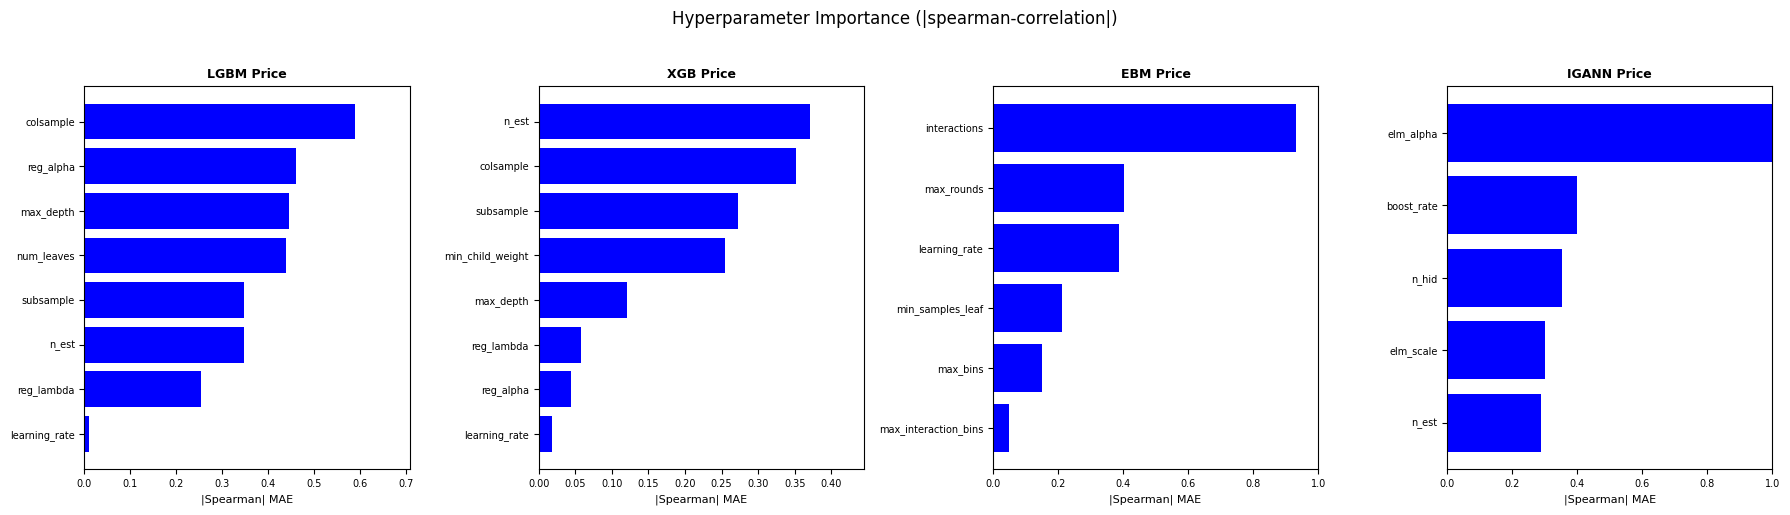

In [ ]:

# --- Parameter Importance aus Trial-CSVs (kernel-restart-sicher) ---
# Proxy-Metrik: |Spearman-Korrelation| zwischen Hyperparameter-Wert und MAE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr

MODELS_DIR = Path("../models")

importance_files = {
    "LGBM Price":    "hpa_trials_lgbm_price.csv",
    "XGB Price":     "hpa_trials_xgb_price.csv",
    "EBM Price":     "hpa_trials_ebm_price.csv",
    "IGANN Price":   "hpa_trials_igann_price.csv",
}

fig, axes = plt.subplots(1, len(importance_files), figsize=(18, 5))

for ax, (name, fname) in zip(axes, importance_files.items()):
    fpath = MODELS_DIR / fname
    if not fpath.exists():
        ax.text(0.5, 0.5, f"Keine Daten\n({fname})", ha="center", va="center",
                transform=ax.transAxes, fontsize=8)
        continue

    df_t = pd.read_csv(fpath)
    completed = df_t[df_t["state"] == "COMPLETE"].copy()
    completed = completed[np.isfinite(completed["value"])]

    if len(completed) < 5:
        ax.text(0.5, 0.5, f"Zu wenig Trials\n(n={len(completed)})", ha="center", va="center",
                transform=ax.transAxes, fontsize=8)
        continue

    # Spalten mit Hyperparameter-Werten (Präfix "params_")
    param_cols = [c for c in completed.columns if c.startswith("params_")]
    if not param_cols:
        ax.text(0.5, 0.5, "Keine Param-Spalten", ha="center", va="center",
                transform=ax.transAxes, fontsize=8)
        continue

    importances = {}
    for col in param_cols:
        vals = completed[col].dropna()
        shared = completed.loc[vals.index, "value"]
        if len(vals) < 5 or vals.nunique() < 2:
            continue
        corr, _ = spearmanr(vals, shared)
        importances[col.replace("params_", "")] = abs(corr)

    if not importances:
        ax.text(0.5, 0.5, "Keine Korrelation berechenbar", ha="center", va="center",
                transform=ax.transAxes, fontsize=8)
        continue

    # Sortieren, kürzen, plotten
    imp_series = pd.Series(importances).sort_values(ascending=False)
    imp_series.index = (imp_series.index
                        .str.replace("colsample_bytree", "colsample")
                        .str.replace("n_estimators", "n_est"))
    top = imp_series.head(8)

    ax.barh(top.index[::-1], top.values[::-1], color=("Blue"))
    ax.set_title(name, fontsize=9, fontweight="bold")
    ax.set_xlabel("|Spearman| MAE", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_xlim(0, min(top.values.max() * 1.2, 1.0))

plt.suptitle("Hyperparameter Importance (|spearman-correlation|)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## 5 · Export & Zusammenfassung

Alle besten Parameter werden als JSON gespeichert (überschreiben die alten Dateien aus Notebooks 03/04).  
Zusätzlich wird eine `hpa_summary.csv` mit dem vollständigen Überblick exportiert.

In [16]:
# --- Vollständige Ergebnis-CSV exportieren ---
summary_path = MODELS_DIR / "hpa_summary.csv"
df_results.to_csv(summary_path, index=False)
print(f"Ergebnis-Zusammenfassung gespeichert: {summary_path}")

# --- Alle Best-Params in einem JSON konsolidieren ---
all_best_params = {}
for model_name, targets in hpa_results.items():
    all_best_params[model_name] = {}
    for target, info in targets.items():
        all_best_params[model_name][target] = info["best_params"]

consolidated_path = MODELS_DIR / "hpa_best_params_all.json"
with open(consolidated_path, "w", encoding="utf-8") as f:
    json.dump(all_best_params, f, indent=2)
print(f"Konsolidierte Best-Params gespeichert: {consolidated_path}")

# --- Abschluss-Report ---
print("\n" + "=" * 60)
print("HPA ABGESCHLOSSEN — FINALE ÜBERSICHT")
print("=" * 60)
for target in [TARGET_PRICE, TARGET_DURATION]:
    print(f"\n  Target: {target}")
    sub = [(m, d[target]["mae"], d[target]["n_trials"])
           for m, d in hpa_results.items() if target in d]
    sub.sort(key=lambda x: x[1])
    for rank, (model, mae, n) in enumerate(sub, 1):
        medal = ["🥇", "🥈", "🥉"][rank - 1] if rank <= 3 else f"  {rank}."
        print(f"    {medal}  {model:12s}  MAE={mae:.4f}  ({n} Trials)")

print("\n✓ Alle Parameter in models/ gespeichert")
print("✓ Nächster Schritt: Modelle mit neuen Best-Params in 03/04 neu trainieren")

Ergebnis-Zusammenfassung gespeichert: <project-root>\\models\hpa_summary.csv
Konsolidierte Best-Params gespeichert: <project-root>\\models\hpa_best_params_all.json

HPA ABGESCHLOSSEN — FINALE ÜBERSICHT

  Target: mietepro_m2
    🥇  Ridge         MAE=1.7536  (188 Trials)
    🥈  IGANN         MAE=1000000000.0000  (2 Trials)

  Target: log_laufzeittage
    🥇  Ridge         MAE=0.9223  (196 Trials)
    🥈  IGANN         MAE=1000000000.0000  (2 Trials)

✓ Alle Parameter in models/ gespeichert
✓ Nächster Schritt: Modelle mit neuen Best-Params in 03/04 neu trainieren
